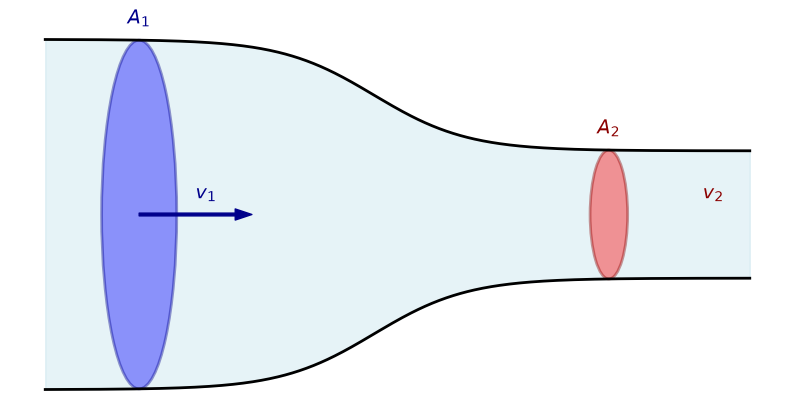

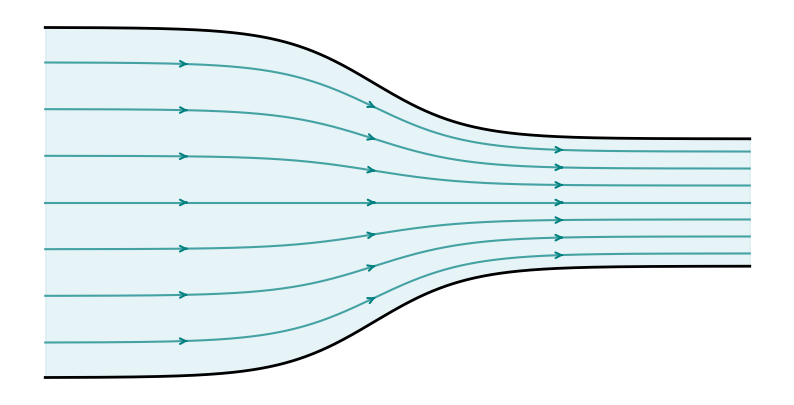

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch

# Funzione per simulare il profilo del tubo (un tubo che si restringe)
def profilo_tubo(x):
    # Usiamo una tangente iperbolica per una transizione fluida
    return 1.5 - 0.7 * np.tanh(x)

x = np.linspace(-3.5, 4, 500)
R = profilo_tubo(x)

# ==========================================
# GRAFICO 1: TUBO DI FLUSSO E SEZIONI
# ==========================================
fig1, ax1 = plt.subplots(figsize=(10, 5))

# Disegna le pareti del tubo
ax1.plot(x, R, color='black', linewidth=2)
ax1.plot(x, -R, color='black', linewidth=2)

# Riempi l'interno per simulare il fluido
ax1.fill_between(x, -R, R, color='lightblue', alpha=0.3)

# Punti di interesse per le due sezioni (A1 e A2)
x1, x2 = -2.5, 2.5
r1, r2 = profilo_tubo(x1), profilo_tubo(x2)

# Disegna le sezioni trasversali (Ellissi per dare l'effetto 3D)
ellisse1 = Ellipse((x1, 0), width=0.8, height=2*r1, edgecolor='darkblue', facecolor='blue', alpha=0.4, linewidth=2)
ellisse2 = Ellipse((x2, 0), width=0.4, height=2*r2, edgecolor='darkred', facecolor='red', alpha=0.4, linewidth=2)
ax1.add_patch(ellisse1)
ax1.add_patch(ellisse2)

# Vettori velocità (v1 e v2)
ax1.annotate('', xy=(x1 + 1.2, 0), xytext=(x1, 0),
             arrowprops=dict(facecolor='darkblue', edgecolor='darkblue', width=2, headwidth=8))
ax1.annotate('', xy=(x2 + 2.0, 0), xytext=(x2, 0),
             arrowprops=dict(facecolor='darkred', edgecolor='darkred', width=2, headwidth=8))

# Testi e label
ax1.text(x1, r1 + 0.2, '$A_1$', fontsize=14, ha='center', color='darkblue')
ax1.text(x1 + 0.6, 0.2, '$v_1$', fontsize=14, color='darkblue')
ax1.text(x2, r2 + 0.2, '$A_2$', fontsize=14, ha='center', color='darkred')
ax1.text(x2 + 1.0, 0.2, '$v_2$', fontsize=14, color='darkred')

# Rimuovi gli assi per un look più pulito, "da libro di testo"
ax1.axis('off')

# Salva l'immagine
fig1.savefig('../../Appunti/img/tubo_di_flusso.png', dpi=300)

# ==========================================
# GRAFICO 2: LINEE DI FLUSSO
# ==========================================
fig2, ax2 = plt.subplots(figsize=(10, 5))

# Pareti del tubo (come prima)
ax2.plot(x, R, color='black', linewidth=2)
ax2.plot(x, -R, color='black', linewidth=2)
ax2.fill_between(x, -R, R, color='lightblue', alpha=0.3)

# Disegna le linee di flusso proporzionali al raggio
num_linee = 7
frazioni = np.linspace(-0.8, 0.8, num_linee)

for fraz in frazioni:
    y_line = fraz * R
    ax2.plot(x, y_line, color='teal', linewidth=1.5, alpha=0.7)
    
    # Aggiungi piccole frecce lungo le linee per indicare la direzione
    for x_arrow in [-2, 0, 2]:
        idx = np.abs(x - x_arrow).argmin()
        ax2.annotate('', xy=(x[idx+1], y_line[idx+1]), xytext=(x[idx], y_line[idx]),
                     arrowprops=dict(arrowstyle='->', color='teal', lw=1.5))

ax2.axis('off')

# Salva l'immagine
fig2.savefig('../../Appunti/img/linee_di_flusso.png', dpi=300)

plt.show()